# Agri-AI Bootcamp — Phase 1, Day 3
## Classification Fundamentals

**Objective:** Train `sklearn` Logistic Regression for a binary **Needs Water** classification task and evaluate using a confusion matrix and ROC-AUC.

### Concepts
- Logistic regression estimates a probability using the sigmoid function.
- A threshold (0.5 by default) converts probability to a Yes/No prediction.
- Cross-entropy / log loss penalizes confident wrong predictions.
- Accuracy alone can be misleading; inspect the confusion matrix and ROC-AUC.

### Dataset caveat
The recommended Kaggle Crop Recommendation dataset (`N`, `P`, `K`, `temperature`, `humidity`, `ph`, `rainfall`, `label`) predicts crop type (`label`), not irrigation need. It does not contain a `Needs_Water` label. This notebook therefore creates a clearly labeled **educational proxy target** from low rainfall to demonstrate binary classification. Since the proxy is defined from rainfall, rainfall is excluded from the predictors to avoid direct target leakage. This proxy is not an agronomic irrigation recommendation. If you have a real irrigation/soil-moisture dataset with Needs Water labels, replace the proxy section with that target.


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, classification_report,
    accuracy_score
)


## 2. Upload and inspect Kaggle Crop Recommendation dataset

In [5]:
from google.colab import files
uploaded = files.upload()

Saving Crop_recommendation.csv to Crop_recommendation.csv


In [6]:
import io
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
df.info()

Shape: (2200, 8)
Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


## 3. Create a binary educational proxy target (Needs Water)
The dataset has no water-needs label. For this practice exercise only, we mark rows with rainfall below the 25th percentile as `Needs_Water=1`. We will **not** use rainfall as a feature, because it directly defines the proxy label. This is only a demonstration label, not a validated farming rule.

In [7]:
# Adapt column name if your dataset differs
rainfall_col = "rainfall"
assert rainfall_col in df.columns, f"Column '{rainfall_col}' not found; inspect df.columns."

data = df.copy()
data[rainfall_col] = pd.to_numeric(data[rainfall_col], errors="coerce")
data = data.dropna(subset=[rainfall_col]).reset_index(drop=True)

rain_threshold = data[rainfall_col].quantile(0.25)
data["Needs_Water"] = (data[rainfall_col] < rain_threshold).astype(int)

print("Rainfall proxy threshold (25th percentile):", rain_threshold)
print(data["Needs_Water"].value_counts().rename(index={0:"No (0)", 1:"Yes (1)"}))
display(data.head())

Rainfall proxy threshold (25th percentile): 64.55168599999999
Needs_Water
No (0)     1650
Yes (1)     550
Name: count, dtype: int64


,N,P,K,temperature,humidity,ph,rainfall,label,Needs_Water
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,0
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,0
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,0
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,0
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,0


## 4. Select predictors and target
Predictors: N, P, K, temperature, humidity and pH if present. We deliberately omit rainfall because it was used to create the proxy target.

In [8]:
candidate_features = ["N", "P", "K", "temperature", "humidity", "ph"]
feature_cols = [c for c in candidate_features if c in data.columns]

if not feature_cols:
    raise ValueError("None of the expected feature columns found. Check dataset columns.")

X = data[feature_cols].apply(pd.to_numeric, errors="coerce")
y = data["Needs_Water"]

valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

print("Features:", feature_cols)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class counts:")
print(y.value_counts())

Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph']
X shape: (2200, 6)
y shape: (2200,)
Class counts:
Needs_Water
0    1650
1     550
Name: count, dtype: int64


## 5. Train/test split (stratified)
Stratification keeps roughly the same class proportion in train and test. The test set remains held out for evaluation.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))
print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True)
      .rename("proportion"))
print("\nTest class distribution:")
print(y_test.value_counts(normalize=True)
      .rename("proportion"))

Train size: 1760
Test size: 440

Train class distribution:
Needs_Water
0    0.75
1    0.25
Name: proportion, dtype: float64

Test class distribution:
Needs_Water
0    0.75
1    0.25
Name: proportion, dtype: float64


## 6. Train Logistic Regression with sklearn
A pipeline standardizes numeric features and fits logistic regression. Scaling is fit only on the training data through the pipeline.

In [10]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model trained.")

Model trained.


## 7. Predict classes and probabilities

In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual Needs Water": y_test.to_numpy(),
    "Predicted Needs Water": y_pred,
    "Probability Needs Water": y_prob
})
display(results.head(10))

,Actual Needs Water,Predicted Needs Water,Probability Needs Water
0,1,0,0.333246
1,0,0,0.019879
2,0,0,0.101926
3,0,0,0.180189
4,0,0,0.214375
5,0,0,0.202903
6,1,0,0.284466
7,0,0,0.043110
8,0,0,0.228710
9,1,0,0.293703


## 8. Confusion matrix
Rows represent actual classes; columns represent predicted classes. For class 1 (Needs Water), a false negative means a dry/needs-water case was missed; a false positive means irrigation need was flagged when it was not according to our proxy.

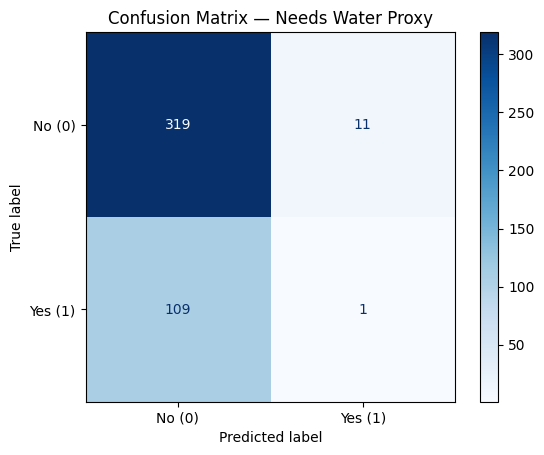

Accuracy: 0.7272727272727273

Classification report:
              precision    recall  f1-score   support

          No       0.75      0.97      0.84       330
         Yes       0.08      0.01      0.02       110

    accuracy                           0.73       440
   macro avg       0.41      0.49      0.43       440
weighted avg       0.58      0.73      0.64       440



In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No (0)", "Yes (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Needs Water Proxy")
plt.show()

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No", "Yes"], zero_division=0))

## 9. ROC-AUC
ROC curve compares true positive rate against false positive rate across probability thresholds. AUC summarizes ranking performance: 0.5 is approximately random ranking, 1.0 is perfect ranking. It does not tell you the best irrigation threshold by itself.

ROC-AUC: 0.6919008264462809


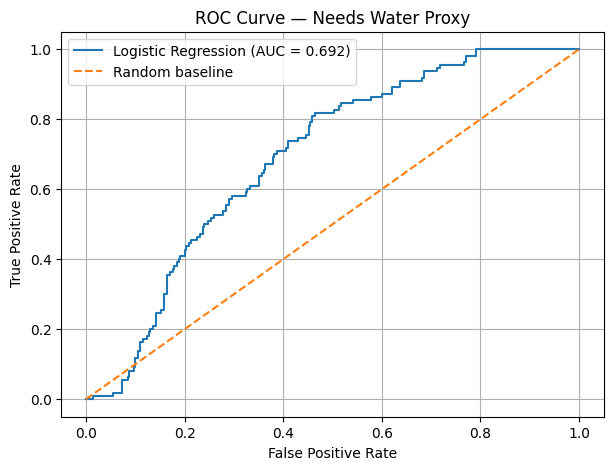

In [13]:
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

print("ROC-AUC:", auc)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Needs Water Proxy")
plt.legend()
plt.grid(True)
plt.show()

## 10. Explore threshold changes
The default threshold is 0.5. Lower thresholds predict more cases as Needs Water, usually increasing recall while potentially increasing false positives. Use this to explore trade-offs—not to set a real irrigation policy.

In [14]:
threshold = 0.35  # experiment with 0.2, 0.35, 0.5, 0.7
y_pred_custom = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_custom, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(y_test, y_pred_custom,
                           target_names=["No", "Yes"],
                           zero_division=0))

Threshold: 0.35
Confusion matrix:
[[278  52]
 [ 81  29]]

Classification report:
              precision    recall  f1-score   support

          No       0.77      0.84      0.81       330
         Yes       0.36      0.26      0.30       110

    accuracy                           0.70       440
   macro avg       0.57      0.55      0.56       440
weighted avg       0.67      0.70      0.68       440



## 11. Example probability prediction
This demonstrates input format only. Values must be in the same units/ranges as the dataset.

In [15]:
# Example row built from the first test sample
example = X_test.iloc[[0]]
example_probability = model.predict_proba(example)[0, 1]
example_prediction = model.predict(example)[0]

print("Example input:")
display(example)
print(f"Probability of proxy Needs Water: {example_probability:.3f}")
print("Predicted class:", "Needs Water" if example_prediction == 1 else "No")

Example input:


,N,P,K,temperature,humidity,ph
1425,117,25,53,29.118585,92.12543,6.413927


Probability of proxy Needs Water: 0.333
Predicted class: No


### Conclusion
Logistic Regression was trained using scikit-learn to classify an educational proxy for water need. The confusion matrix shows correct and incorrect predictions by class, while ROC-AUC evaluates ranking performance across thresholds. The dataset does not provide true irrigation labels, so results cannot be used as a real irrigation decision system. A real model requires labeled irrigation need data, such as soil moisture and crop/weather context with expert-verified labels.

